#### Imports


In [2]:
from pathlib import Path
import json
import numpy as np
import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit

from tensorflow.keras import layers, models

# Full data loader

In [3]:
dataset_dirs = {
    "phone": Path("har_stage2_production_phones_v1"),
    "watch": Path("har_stage2_production_watch_v1"),
}

class_names = [
    "bike",
    "sit",
    "stairsdown",
    "stairsup",
    "stand",
    "walk"
]

label_to_index = {
    "bike": 0,
    "sit": 1,
    "stairsdown": 2,
    "stairsup": 3,
    "stand": 4,
    "walk": 5
}

all_X = []
all_y = []
all_participants = []
all_sources = []
all_metadata = []


for source_name, dataset_dir in dataset_dirs.items():
    print(f"\nLoading {source_name}: {dataset_dir}")

    shard_paths = sorted(dataset_dir.glob("windows-*.npz"))
    print("Shards found:", len(shard_paths))

    source_X = []
    source_y = []
    source_participants = []

    for shard_path in shard_paths:
        with np.load(shard_path, allow_pickle=False) as z:
            X = z["X"].astype(np.float32)
            labels = z["labels"]
            metadata = z["metadata"]

            y = np.array([
                label_to_index[str(label)]
                for label in labels
            ], dtype=np.int64)

            participants = np.array([
                json.loads(item)["User"]
                for item in metadata
            ])
            
            all_metadata.extend(metadata)

        source_X.append(X)
        source_y.append(y)
        source_participants.append(participants)

    X_source = np.concatenate(source_X, axis=0)
    y_source = np.concatenate(source_y, axis=0)
    participants_source = np.concatenate(source_participants, axis=0)

    print("Windows:", X_source.shape[0])
    print("X shape:", X_source.shape)
    print("Participants:", np.unique(participants_source))

    all_X.append(X_source)
    all_y.append(y_source)
    all_participants.append(participants_source)
    all_sources.append(
        np.full(len(X_source), source_name, dtype="<U16")
    )

X = np.concatenate(all_X, axis=0)
y = np.concatenate(all_y, axis=0)
participant_ids = np.concatenate(all_participants, axis=0)
source_ids = np.concatenate(all_sources, axis=0)
metadata = np.array(all_metadata)

print("\nCombined dataset")
print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)
print("Participants:", np.unique(participant_ids))
print("Sources:", np.unique(source_ids))
print("Windows per source:")

print("Metadata records:", len(metadata))
print("Windows:", len(X))

assert len(metadata) == len(X)

for source in np.unique(source_ids):
    print(f"{source}: {np.sum(source_ids == source)}")


Loading phone: har_stage2_production_phones_v1
Shards found: 58
Windows: 32160
X shape: (32160, 128, 6)
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']

Loading watch: har_stage2_production_watch_v1
Shards found: 25
Windows: 5032
X shape: (5032, 128, 6)
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']

Combined dataset
X: (37192, 128, 6) float32
y: (37192,) int64
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']
Sources: ['phone' 'watch']
Windows per source:
Metadata records: 37192
Windows: 37192
phone: 32160
watch: 5032


#### To see specific devices

In [4]:
device_ids = np.array([
    json.loads(item)["Device"]
    for item in metadata
])

print("device_ids shape:", device_ids.shape)
print("Unique devices:", np.unique(device_ids))

assert device_ids.shape[0] == X.shape[0]

device_ids shape: (37192,)
Unique devices: ['gear_1' 'gear_2' 'lgwatch_1' 'lgwatch_2' 'nexus4_1' 'nexus4_2' 's3_1'
 's3_2' 's3mini_1' 's3mini_2']


In [5]:
assert X.ndim == 3
assert X.shape[1:] == (128, 6)
assert X.dtype == np.float32

assert y.ndim == 1
assert len(y) == len(X)
assert len(participant_ids) == len(X)
assert len(source_ids) == len(X)

assert set(np.unique(y)) == set(range(6))
assert set(np.unique(source_ids)) == {"phone", "watch"}

In [6]:
phone_count = int(np.sum(source_ids == "phone"))
watch_count = int(np.sum(source_ids == "watch"))

print(f"Phone windows: {phone_count}")
print(f"Watch windows: {watch_count}")
print(f"Total windows: {len(X)}")

assert phone_count == 32160, (
    f"Expected 32160 phone windows, got {phone_count}"
)

assert watch_count == 5032, (
    f"Expected 5032 watch windows, got {watch_count}"
)

assert len(X) == 37192, (
    f"Expected 37192 total windows, got {len(X)}"
)

print("Participants:", np.unique(participant_ids))
print("Sources:", np.unique(source_ids))
print("Phone windows:", phone_count)
print("Watch windows:", watch_count)

Phone windows: 32160
Watch windows: 5032
Total windows: 37192
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']
Sources: ['phone' 'watch']
Phone windows: 32160
Watch windows: 5032


In [7]:
print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)
print("Participants:", np.unique(participant_ids))
print("Sources:", np.unique(source_ids))

print("\nWindows per source:")
for source in np.unique(source_ids):
    print(source, np.sum(source_ids == source))

print("\nWindows per class:")
for index, name in enumerate(class_names):
    print(name, np.sum(y == index))

X: (37192, 128, 6) float32
y: (37192,) int64
Participants: ['a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i']
Sources: ['phone' 'watch']

Windows per source:
phone 32160
watch 5032

Windows per class:
bike 5494
sit 7330
stairsdown 4784
stairsup 5797
stand 6256
walk 7531


# Split data


In [8]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, temp_idx = next(
    splitter.split(X, y, groups=participant_ids)
)

X_train, y_train = X[train_idx], y[train_idx]
X_temp, y_temp = X[temp_idx], y[temp_idx]

# Split the remaining participants into validation and test
temp_participants = np.unique(participant_ids[temp_idx])

rng = np.random.default_rng(42)
rng.shuffle(temp_participants)

n_val = max(1, len(temp_participants) // 2)
val_participants = set(temp_participants[:n_val])
test_participants = set(temp_participants[n_val:])

val_mask = np.isin(participant_ids, list(val_participants))
test_mask = np.isin(participant_ids, list(test_participants))

print("Validation participants:", val_participants)
print("Test participants:", test_participants)

X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

Validation participants: {np.str_('h')}
Test participants: {np.str_('b')}


#### Verify


In [9]:
train_participants = set(np.unique(participant_ids[train_idx]))
val_participants = set(np.unique(participant_ids[val_mask]))
test_participants = set(np.unique(participant_ids[test_mask]))

print("Train participants:", sorted(train_participants))
print("Validation participants:", sorted(val_participants))
print("Test participants:", sorted(test_participants))

print("\nTrain windows:", len(y_train))
print("Validation windows:", len(y_val))
print("Test windows:", len(y_test))

assert train_participants.isdisjoint(val_participants)
assert train_participants.isdisjoint(test_participants)
assert val_participants.isdisjoint(test_participants)

Train participants: [np.str_('a'), np.str_('c'), np.str_('d'), np.str_('e'), np.str_('f'), np.str_('g'), np.str_('i')]
Validation participants: [np.str_('h')]
Test participants: [np.str_('b')]

Train windows: 28581
Validation windows: 4029
Test windows: 4582


In [10]:
for split_name, y_split in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test),
]:
    print(f"\n{split_name} class counts:")

    for index, name in enumerate(class_names):
        print(f"{name}: {np.sum(y_split == index)}")


Train class counts:
bike: 4040
sit: 5769
stairsdown: 3583
stairsup: 4356
stand: 5086
walk: 5747

Validation class counts:
bike: 518
sit: 852
stairsdown: 661
stairsup: 712
stand: 471
walk: 815

Test class counts:
bike: 936
sit: 709
stairsdown: 540
stairsup: 729
stand: 699
walk: 969


# Normalize

In [11]:
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)

# CNN-LSTM model

In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models

NUM_CLASSES = len(class_names)
INPUT_SHAPE = X_train.shape[1:]

model = models.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    normalizer,

    layers.Conv1D(64, kernel_size=5, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(128, kernel_size=5, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2),

    layers.LSTM(64, return_sequences=True),
    layers.LSTM(32),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 128, 6)         │            13 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,179 (422.58 KB)

 Trainable params: 107,782 (421.02 KB)

 Non-trainable params: 397 (1.55 KB)

# Train model

In [13]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 17s 33ms/step - accuracy: 0.8895 - loss: 0.3681 - val_accuracy: 0.9099 - val_loss: 0.2090 - learning_rate: 0.0010
Epoch 2/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.9537 - loss: 0.1584 - val_accuracy: 0.8943 - val_loss: 0.2686 - learning_rate: 0.0010
Epoch 3/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.9605 - loss: 0.1321 - val_accuracy: 0.9000 - val_loss: 0.2793 - learning_rate: 0.0010
Epoch 4/50
445/447 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9731 - loss: 0.0976
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
447/447 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.9732 - loss: 0.0973 - val_accuracy: 0.9116 - val_loss: 0.2720 - learning_rate: 0.0010
Epoch 5/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - accuracy: 0.9816 - loss: 0.0635 - val_accuracy: 0.9260 - val_loss: 0.2831 - learning_rate: 5.0000e-04
Epoch 6/50
447/447 ━━━━━━━━━━━━━━━━━━━━ 12s 27ms/step - accuracy: 0.9868 -

# Test best

In [14]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.6086
Test accuracy: 0.7896


# Predictions and confusion matrix

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

        bike     0.9628    0.9669    0.9648       936
         sit     0.4750    0.4147    0.4428       709
  stairsdown     0.9141    0.8870    0.9004       540
    stairsup     0.8857    0.9355    0.9099       729
       stand     0.4440    0.4707    0.4569       699
        walk     0.9403    0.9587    0.9494       969

    accuracy                         0.7896      4582
   macro avg     0.7703    0.7723    0.7707      4582
weighted avg     0.7854    0.7896    0.7870      4582

[[905   6  11   5   6   3]
 [  8 294   0   1 406   0]
 [  0   0 479  33   0  28]
 [  0   0  23 682   0  24]
 [ 27 319   3  17 329   4]
 [  0   0   8  32   0 929]]


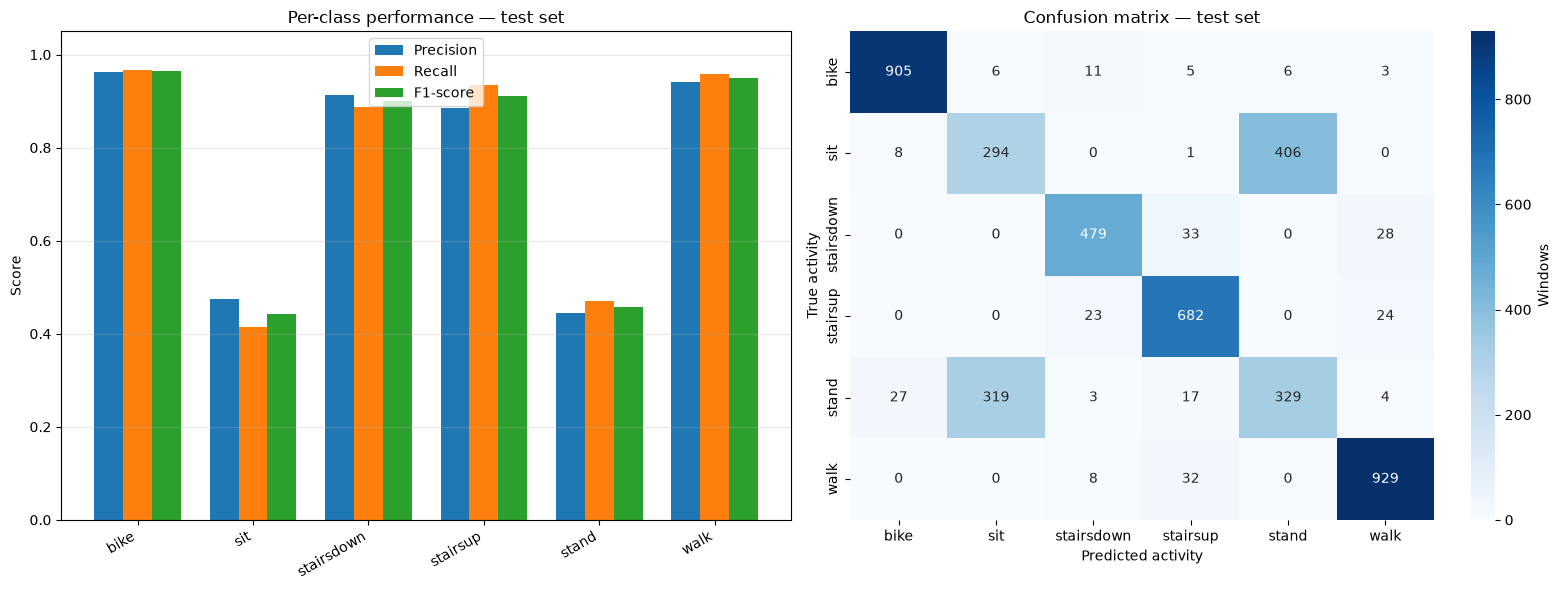

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Make predictions from the current trained model
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Compute metrics directly from the current test labels and predictions
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    output_dict=True
)

cm = confusion_matrix(y_test, y_pred)

# Extract per-class metrics in the same order as class_names
precision = [report[name]["precision"] for name in class_names]
recall = [report[name]["recall"] for name in class_names]
f1 = [report[name]["f1-score"] for name in class_names]
support = [report[name]["support"] for name in class_names]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: precision, recall, and F1-score
x = np.arange(len(class_names))
width = 0.25

axes[0].bar(x - width, precision, width, label="Precision")
axes[0].bar(x, recall, width, label="Recall")
axes[0].bar(x + width, f1, width, label="F1-score")

axes[0].set_xticks(x)
axes[0].set_xticklabels(class_names, rotation=30, ha="right")
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Score")
axes[0].set_title("Per-class performance — test set")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Right: confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Windows"},
    ax=axes[1]
)

axes[1].set_xlabel("Predicted activity")
axes[1].set_ylabel("True activity")
axes[1].set_title("Confusion matrix — test set")

plt.tight_layout()
plt.show()

# Per device

In [20]:
import json
import numpy as np
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Create the activity-name list in the same order as the model outputs
label_names = [None] * len(label_to_index)

for label, index in label_to_index.items():
    label_names[index] = label

# Create predictions for the test set
y_pred = np.argmax(
    model.predict(X_test, verbose=0),
    axis=1
)

# Get the device ID for every test window
test_devices = device_ids[test_mask]

# Calculate metrics separately for every device
device_results = {}

for device in np.unique(test_devices):
    device_mask = test_devices == device

    y_true_device = y_test[device_mask]
    y_pred_device = y_pred[device_mask]

    device_results[device] = {
        "windows": int(device_mask.sum()),
        "accuracy": accuracy_score(y_true_device, y_pred_device),
        "macro_f1": f1_score(
            y_true_device,
            y_pred_device,
            average="macro",
            zero_division=0
        )
    }

# Print a clean summary
print("Per-device test results:\n")

for device in sorted(device_results):
    result = device_results[device]

    print(
        f"{device}: "
        f"windows={result['windows']}, "
        f"accuracy={result['accuracy']:.4f}, "
        f"macro_f1={result['macro_f1']:.4f}"
    )

print("\nOverall test accuracy:", accuracy_score(y_test, y_pred))
print(
    "Overall test macro F1:",
    f1_score(y_test, y_pred, average="macro", zero_division=0)
)

print("\nClassification report by device:\n")

for device in sorted(device_results):
    device_mask = test_devices == device

    print(f"Device: {device}")
    print(
        classification_report(
            y_test[device_mask],
            y_pred[device_mask],
            labels=np.arange(len(label_names)),
            target_names=label_names,
            zero_division=0
        )
    )

Per-device test results:

gear_1: windows=94, accuracy=0.6170, macro_f1=0.5963
gear_2: windows=10, accuracy=0.1000, macro_f1=0.0455
lgwatch_1: windows=718, accuracy=0.7103, macro_f1=0.6809
nexus4_1: windows=430, accuracy=0.9233, macro_f1=0.8972
nexus4_2: windows=473, accuracy=0.8161, macro_f1=0.7754
s3_1: windows=917, accuracy=0.7950, macro_f1=0.7589
s3_2: windows=871, accuracy=0.7910, macro_f1=0.7518
s3mini_1: windows=1069, accuracy=0.7933, macro_f1=0.7702

Overall test accuracy: 0.7896115233522479
Overall test macro F1: 0.7707104262995136

Classification report by device:

Device: gear_1
              precision    recall  f1-score   support

        bike       0.62      0.87      0.72        15
         sit       0.82      0.69      0.75        26
  stairsdown       0.50      0.43      0.46         7
    stairsup       0.41      0.69      0.51        16
       stand       1.00      0.62      0.76        13
        walk       0.50      0.29      0.37        17

    accuracy           

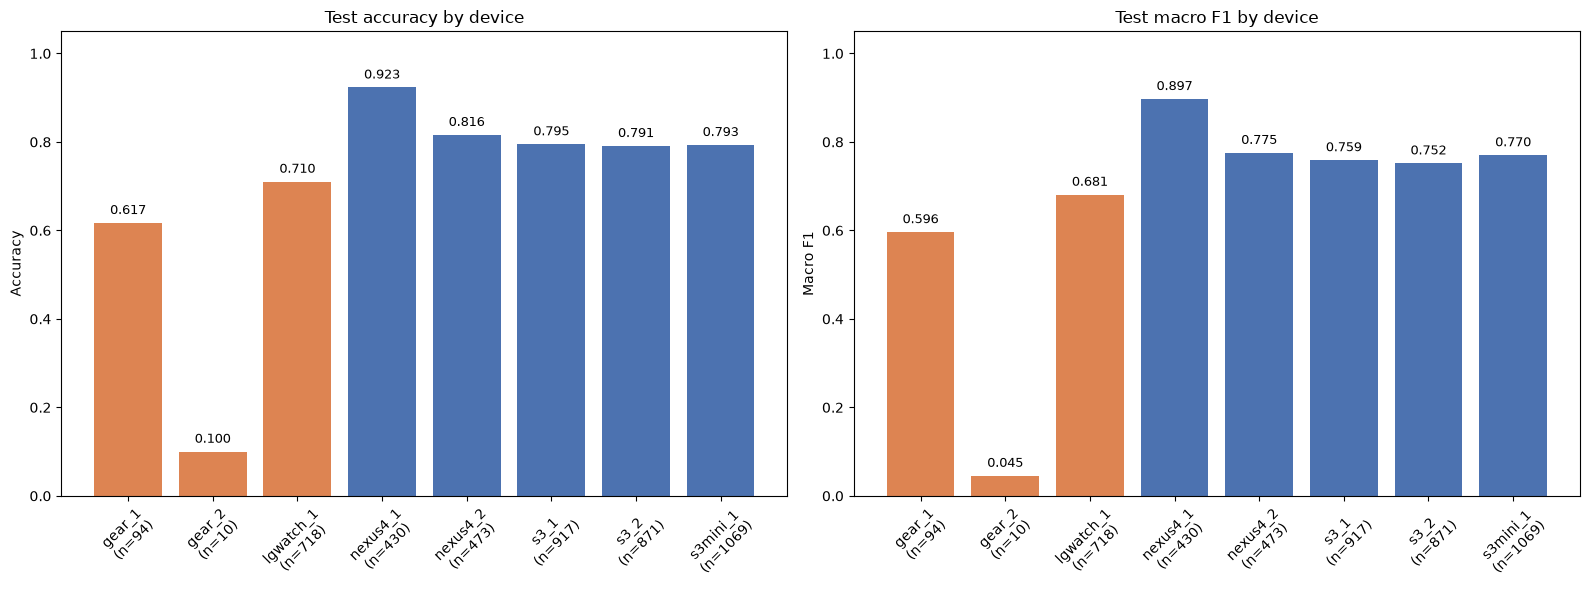

In [21]:
import matplotlib.pyplot as plt

# Sort devices alphabetically for a stable plot
devices = sorted(device_results.keys())

accuracies = [device_results[device]["accuracy"] for device in devices]
macro_f1s = [device_results[device]["macro_f1"] for device in devices]
window_counts = [device_results[device]["windows"] for device in devices]

# Label each bar with the device name and number of test windows
device_labels = [
    f"{device}\n(n={device_results[device]['windows']})"
    for device in devices
]

# Color phone devices blue and watch devices orange
phone_devices = {
    "nexus4_1",
    "nexus4_2",
    "s3_1",
    "s3_2",
    "s3mini_1",
    "s3mini_2"
}

colors = [
    "#4C72B0" if device in phone_devices else "#DD8452"
    for device in devices
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy plot
axes[0].bar(device_labels, accuracies, color=colors)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Test accuracy by device")
axes[0].tick_params(axis="x", rotation=45)

for index, value in enumerate(accuracies):
    axes[0].text(
        index,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

# Macro F1 plot
axes[1].bar(device_labels, macro_f1s, color=colors)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Macro F1")
axes[1].set_title("Test macro F1 by device")
axes[1].tick_params(axis="x", rotation=45)

for index, value in enumerate(macro_f1s):
    axes[1].text(
        index,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [23]:
from collections import Counter
import pandas as pd

test_devices = device_ids[test_mask]

rows = []

for device in sorted(np.unique(test_devices)):
    device_mask = test_devices == device
    activity_counts = Counter(y_test[device_mask])

    row = {
        "Device": device,
        "Windows": device_mask.sum(),
    }

    for activity_index, activity_name in enumerate(label_names):
        row[activity_name] = activity_counts.get(activity_index, 0)

    rows.append(row)

device_activity_table = pd.DataFrame(rows)

print(device_activity_table.to_string(index=False))

   Device  Windows  bike  sit  stairsdown  stairsup  stand  walk
   gear_1       94    15   26           7        16     13    17
   gear_2       10    10    0           0         0      0     0
lgwatch_1      718   150  122          74        95    150   127
 nexus4_1      430   102   63          50        76     51    88
 nexus4_2      473   107   56          61        72     80    97
     s3_1      917   160  132         118       160    139   208
     s3_2      871   197  137          97       133    117   190
 s3mini_1     1069   195  173         133       177    149   242


Per-device-family test results:

gear: windows=104, accuracy=0.5673, macro_f1=0.5461
lgwatch: windows=718, accuracy=0.7103, macro_f1=0.6809
nexus4: windows=903, accuracy=0.8671, macro_f1=0.8412
s3: windows=1788, accuracy=0.7931, macro_f1=0.7555
s3mini: windows=1069, accuracy=0.7933, macro_f1=0.7702

Overall test accuracy: 0.7896115233522479
Overall test macro F1: 0.7707104262995136

Test windows per device family and activity:

Device family  Windows  bike  sit  stairsdown  stairsup  stand  walk
         gear      104    25   26           7        16     13    17
      lgwatch      718   150  122          74        95    150   127
       nexus4      903   209  119         111       148    131   185
           s3     1788   357  269         215       293    256   398
       s3mini     1069   195  173         133       177    149   242

Classification report by device family:

Device family: gear
              precision    recall  f1-score   support

        bike       0.64      0.56    

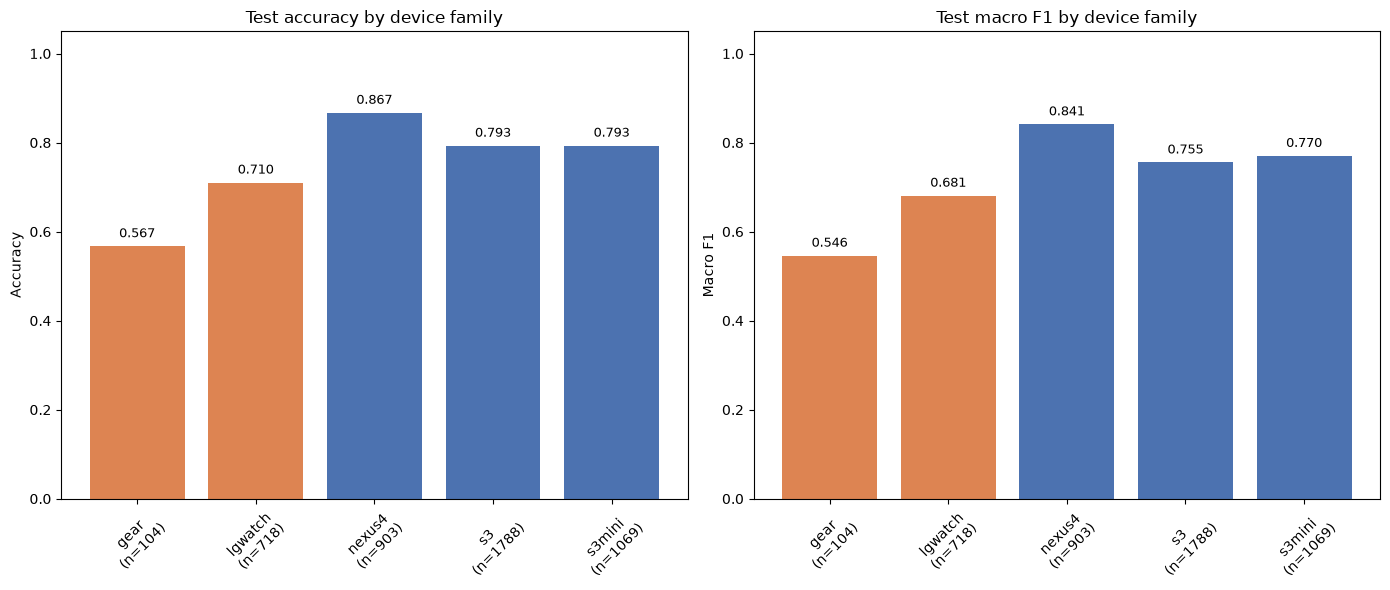

In [24]:
import json
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Map each individual device to its device family
device_family_map = {
    "gear_1": "gear",
    "gear_2": "gear",
    "lgwatch_1": "lgwatch",
    "lgwatch_2": "lgwatch",
    "nexus4_1": "nexus4",
    "nexus4_2": "nexus4",
    "s3_1": "s3",
    "s3_2": "s3",
    "s3mini_1": "s3mini",
    "s3mini_2": "s3mini"
}

# Create a device-family label for every window
device_families = np.array([
    device_family_map[device]
    for device in device_ids
])

# Create the activity-name list in the same order as the model outputs
label_names = [None] * len(label_to_index)

for label, index in label_to_index.items():
    label_names[index] = label

# Create predictions for the test set
y_pred = np.argmax(
    model.predict(X_test, verbose=0),
    axis=1
)

# Get the device family for every test window
test_device_families = device_families[test_mask]

# Calculate metrics separately for every device family
family_results = {}

for family in np.unique(test_device_families):
    family_mask = test_device_families == family

    y_true_family = y_test[family_mask]
    y_pred_family = y_pred[family_mask]

    family_results[family] = {
        "windows": int(family_mask.sum()),
        "accuracy": accuracy_score(y_true_family, y_pred_family),
        "macro_f1": f1_score(
            y_true_family,
            y_pred_family,
            average="macro",
            zero_division=0
        )
    }

# Print metric summary
print("Per-device-family test results:\n")

for family in sorted(family_results):
    result = family_results[family]

    print(
        f"{family}: "
        f"windows={result['windows']}, "
        f"accuracy={result['accuracy']:.4f}, "
        f"macro_f1={result['macro_f1']:.4f}"
    )

print("\nOverall test accuracy:", accuracy_score(y_test, y_pred))
print(
    "Overall test macro F1:",
    f1_score(y_test, y_pred, average="macro", zero_division=0)
)

# Print activity counts for every device family
print("\nTest windows per device family and activity:\n")

family_activity_rows = []

for family in sorted(np.unique(test_device_families)):
    family_mask = test_device_families == family
    activity_counts = Counter(y_test[family_mask])

    row = {
        "Device family": family,
        "Windows": family_mask.sum()
    }

    for activity_index, activity_name in enumerate(label_names):
        row[activity_name] = activity_counts.get(activity_index, 0)

    family_activity_rows.append(row)

family_activity_table = pd.DataFrame(family_activity_rows)

print(family_activity_table.to_string(index=False))

# Print classification report for every device family
print("\nClassification report by device family:\n")

for family in sorted(family_results):
    family_mask = test_device_families == family

    print(f"Device family: {family}")
    print(
        classification_report(
            y_test[family_mask],
            y_pred[family_mask],
            labels=np.arange(len(label_names)),
            target_names=label_names,
            zero_division=0
        )
    )

# Plot accuracy and macro F1 by device family
families = sorted(family_results.keys())

accuracies = [family_results[family]["accuracy"] for family in families]
macro_f1s = [family_results[family]["macro_f1"] for family in families]

family_labels = [
    f"{family}\n(n={family_results[family]['windows']})"
    for family in families
]

watch_families = {"gear", "lgwatch"}

colors = [
    "#DD8452" if family in watch_families else "#4C72B0"
    for family in families
]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].bar(family_labels, accuracies, color=colors)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Test accuracy by device family")
axes[0].tick_params(axis="x", rotation=45)

for index, value in enumerate(accuracies):
    axes[0].text(
        index,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

axes[1].bar(family_labels, macro_f1s, color=colors)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Macro F1")
axes[1].set_title("Test macro F1 by device family")
axes[1].tick_params(axis="x", rotation=45)

for index, value in enumerate(macro_f1s):
    axes[1].text(
        index,
        value + 0.02,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

Whats up world!